# Exploratory Data Analysis - Gene Ontology

## Environment


In [1]:
# Imports

from pathlib import Path
import numpy as np
import pandas as pd
import re
import string
import requests
from tqdm.auto import tqdm
from itertools import product
import warnings
import pickle
import os

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from obonet import read_obo
import networkx as nx
import nltk
import spacy
from spacy.lang.en.stop_words import STOP_WORDS

from yellowbrick.cluster import KElbowVisualizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, SpectralEmbedding
from sklearn.metrics import silhouette_score, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.neighbors import NearestNeighbors
import hdbscan
import umap

import torch
from torch_geometric.data import Data


from datasets import Dataset
from sentence_transformers import SentenceTransformer

# disable warnings
warnings.filterwarnings("ignore")

# download up-to-date stopwords
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("punkt", quiet=True)

# root directory
root = Path("/home/clever/datascience/projects/prot2go")

# Creates directories to save results
clustering_folder = root / "clustering/"
clustering_folder.mkdir(parents=True, exist_ok=True)
embeddings_folder = root / "embeddings"
embeddings_folder.mkdir(parents=True, exist_ok=True)
metadata_folder = root / "metadata"
metadata_folder.mkdir(parents=True, exist_ok=True)
datasets_folder = root / "datasets"
datasets_folder.mkdir(parents=True, exist_ok=True)


# Set CUDA
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
os.environ["TORCH"] = torch.__version__
print("Device:", device)

Device: cuda


In [2]:
# Exploratory Data Analysis (EDA) and plotting

def plot_graph_centrality(
    G: nx.Graph,
    centrality_type: str = "degree",
    num_top_nodes: int = 100,
    iterations: int = 100,
    figure_size: tuple = (16, 16),
    plot_labels: bool = True,
    node_color_scale: bool = True,
    node_alpha: float = 0.5,
    edge_alpha: float = 0.4,
    cmap: plt.cm = plt.cm.viridis,
    fixed_node_size: int = 300,
    font_color: str = "black",
    font_size: int = 10,
    font_alpha: float = 0.3,
):
    """
    Plots a graph focusing on the top nodes according to selected centrality measures, visually emphasizing
    the importance of nodes in a network based on the specified centrality measure. This function supports various
    centrality metrics and visual customization options.

    Args:
        G (nx.Graph): The graph to plot.
        centrality_type (str): Type of centrality measure ('degree', 'eigenvector', 'betweenness', 'closeness', 'clustering').
        num_top_nodes (int, optional): Number of top nodes to plot based on the centrality measure.
        iterations (int, optional): Number of iterations for the layout algorithm.
        figure_size (tuple, optional): Dimensions of the figure (width, height).
        plot_labels (bool, optional): Flag to determine whether labels should be displayed for nodes.
        node_color_scale (bool, optional): Whether to scale node colors by the selected centrality measure.
        node_alpha (float, optional): Transparency level of nodes.
        edge_alpha (float, optional): Transparency level of edges.
        cmap (Colormap, optional): Colormap for node colors if scaled.
        fixed_node_size (int, optional): Fixed size for all nodes if not scaling by centrality measure.
        font_color (str, optional): Color of the font for node labels.
        font_size (int, optional): Font size for node labels.
        font_alpha (float, optional): Transparency level of font labels.

    Raises:
        ValueError: If an invalid centrality measure is specified.
    Returns:
        A python dictionary with node ids as keys and centrality as values in descending order of centrality.

    Example usage:
        G = nx.gnp_random_graph(100, 0.05)
        plot_graph_centrality(
            G, centrality_type="closeness", num_top_nodes=10, node_color_scale=True
        )
    """

    # Select and compute the appropriate centrality measure based on input
    centrality_methods = {
        "degree": lambda G: dict(G.degree()),
        "eigenvector": nx.eigenvector_centrality,
        "betweenness": nx.betweenness_centrality,
        "closeness": nx.closeness_centrality,
        "clustering": nx.clustering,
    }

    if centrality_type not in centrality_methods:
        raise ValueError(f"Invalid centrality measure specified: {centrality_type}")

    centrality = centrality_methods[centrality_type](G)

    # Sort nodes by selected centrality and select the top nodes
    top_nodes = sorted(centrality.items(), key=lambda x: x[1], reverse=True)[
        :num_top_nodes
    ]
    subgraph = G.subgraph([node for node, _ in top_nodes])

    # Set up color and size mappings based on centrality
    if node_color_scale:
        node_color = [centrality[node] for node in subgraph.nodes()]
        node_size = [
            centrality[node] * 1000 if centrality_type != "degree" else centrality[node]
            for node in subgraph.nodes()
        ]
    else:
        node_color = "skyblue"
        node_size = [fixed_node_size] * len(subgraph)

    plt.figure(figsize=figure_size)
    pos = nx.spring_layout(subgraph, iterations=iterations)

    nx.draw_networkx_nodes(
        subgraph,
        pos,
        node_size=node_size,
        node_color=node_color,
        alpha=node_alpha,
        cmap=cmap,
    )
    nx.draw_networkx_edges(subgraph, pos, alpha=edge_alpha)

    if plot_labels:
        labels = {node: f"{node}\n{centrality[node]:.2f}" for node in subgraph.nodes()}
        nx.draw_networkx_labels(
            subgraph,
            pos,
            labels=labels,
            font_color=font_color,
            font_size=font_size,
            alpha=font_alpha,
        )

    plt.title(f"Graph with top {num_top_nodes} nodes by {centrality_type} centrality")
    plt.axis("off")
    plt.show()

    return dict(top_nodes)


def plot_centrality_histogram(G: nx.Graph, centrality_type="degree", bins=15):
    """
    Plots a histogram for a specified centrality measure of a graph.

    Parameters:
    - G (nx.Graph): The graph from which to plot centrality distribution.
    - centrality_type (str): The type of centrality measure to plot ('degree', 'eigenvector', 'betweenness', 'closeness', 'clustering').
    - bins (int): Number of bins to use in the histogram.

    Returns:
        A python dictionary with node ids as keys and centrality as values in descending order of centrality.

    """
    if centrality_type == "degree":
        centrality = dict(G.degree())
        title = "Degree Centrality Distribution"
    elif centrality_type == "eigenvector":
        centrality = nx.eigenvector_centrality(G)
        title = "Eigenvector Centrality Distribution"
    elif centrality_type == "betweenness":
        centrality = nx.betweenness_centrality(G)
        title = "Betweenness Centrality Distribution"
    elif centrality_type == "closeness":
        centrality = nx.closeness_centrality(G)
        title = "Closeness Centrality Distribution"
    elif centrality_type == "clustering":
        centrality = nx.clustering(G)
        title = "Clustering Coefficient Distribution"
    else:
        raise ValueError(
            "Invalid centrality measure. Choose 'degree', 'eigenvector', 'betweenness', 'closeness', or 'clustering'."
        )

    # Convert centrality values to a list
    centrality_values = list(centrality.values())

    # Set up the plot
    plt.figure(figsize=(8, 5))
    sns.histplot(centrality_values, bins=bins, color="skyblue", edgecolor="black")
    plt.title(title)
    plt.xlabel(centrality_type.capitalize() + " Centrality")
    plt.ylabel("Frequency")
    plt.show()

    return dict(sorted(centrality.items(), key=lambda x: x[1], reverse=True))


def annotate_proteins(ids_to_annotate, fetch_go=True):
    """
    Retrieves annotations selectively from UniProt and optionally Gene Ontology (GO) for a list of UniProt IDs.

    Parameters:
    - ids_to_annotate (list): List of UniProt IDs to retrieve annotations for.
    - fetch_go (bool): If True, fetches GO annotations.

    Returns:
    - tuple: A pandas DataFrame for UniProt annotations, and optionally another DataFrame for GO annotations.
    """
    uniprot_annotations = []
    go_annotations_list = []

    for protein_id in tqdm(ids_to_annotate, desc="Fetching Annotations"):
        # UniProt Full Annotations - Always fetched
        try:
            url = f"https://www.uniprot.org/uniprot/{protein_id}.txt"
            response = requests.get(url)
            if response.ok:
                uniprot_annotations.append(
                    {"UniProt_ID": protein_id, "UniProt_Annotation": response.text}
                )
        except Exception as e:
            print(
                f"UniProt full annotation retrieval failed for {protein_id}. Error: {str(e)}"
            )

        # GO Annotations - Fetched if requested

        # Define mapping for categorical aspects:
        aspect_mapping = {
            "C": "cellular_component",
            "F": "molecular_function",
            "P": "biological_process",
        }
        if fetch_go and response.ok:
            go_annotations = []
            try:
                data = response.text
                for line in data.splitlines():
                    if line.startswith("DR   GO;"):
                        go_info = line.split("; ")
                        go_id = "GO:" + go_info[1].split(":")[1]
                        aspect, go_term = go_info[2].rstrip(".").split(":")
                        go_annotations.append(
                            {
                                "uniprot_id": protein_id,
                                "go_id": go_id,
                                "name": go_term,
                                "aspect": aspect_mapping.get(aspect, aspect),
                            }
                        )
                go_annotations_list.extend(go_annotations)
            except Exception as e:
                print(
                    f"GO annotation retrieval failed for {protein_id}. Error: {str(e)}"
                )

    # Convert lists to DataFrames
    uniprot_df = pd.DataFrame(uniprot_annotations)
    if fetch_go:
        go_df = pd.DataFrame(go_annotations_list)
        return uniprot_df, go_df
    else:
        return (
            uniprot_df,
            pd.DataFrame(),
        )  # Return an empty DataFrame if GO was not fetched


def plot_tfidf(
    texts,
    max_df=0.85,
    min_df=2,
    n_gram_range=(1, 2),
    top_n=25,
):
    """
    Computes and visualizes the top N terms with the highest TF-IDF scores.

    Parameters:
    - texts (iterable): Iterable (list, np.array, pd.Series) containing the text data.
    - max_df (float): Maximum document frequency allowed for tokens. This is used to ignore terms that appear too frequently and are not informative.
    - min_df (int or float): Minimum document occurrence required for tokens. If an integer, specifies the number of documents a term must appear in to be considered; if a float, specifies the fraction of documents.
    - n_gram_range (tuple): The lower and upper boundary of the range of n-values for different n-grams to be extracted.
    - top_n (int): Number of top terms to visualize.

    Returns:
    - None: Displays a bar chart of the top terms with their TF-IDF scores.
    """
    # Ensure input is in an appropriate format for vectorization
    if isinstance(texts, pd.Series):
        texts = texts.values  # Convert pd.Series to np.array
    elif isinstance(texts, list):
        texts = np.array(texts)  # Convert list to np.array

    # Initialize the TfidfVectorizer
    vectorizer = TfidfVectorizer(max_df=max_df, min_df=min_df, ngram_range=n_gram_range)

    # Generate the TF-IDF matrix
    tf_idf_matrix = vectorizer.fit_transform(texts)
    features = vectorizer.get_feature_names_out()

    # Compute the maximum TF-IDF score for each feature across all documents
    max_scores = np.max(tf_idf_matrix, axis=0).toarray().flatten()

    # Obtain sorted indices (descending order) and select the top N features
    sorted_indices = np.argsort(max_scores)[::-1][:top_n]
    sorted_features = features[sorted_indices]
    sorted_scores = max_scores[sorted_indices]

    # Create a bar chart
    plt.figure(figsize=(12, 8))
    bars = plt.barh(sorted_features, sorted_scores, color="green")
    plt.xlabel("Max TF-IDF Score")
    plt.title(f"Top {top_n} Terms with Highest TF-IDF Scores")
    plt.gca().invert_yaxis()  # Invert y-axis to have the highest score on top

    # Add data labels to each bar
    for bar in bars:
        plt.gca().text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}",
            ha="left",
            va="center",
            color="black",
        )

    # Show plot with interactive mode on
    plt.grid(False)
    plt.show()


# Data visualization of GO aspects


def plot_ratio(df: pd.DataFrame) -> None:
    """
    Plots the aspect ratio of GO terms from a given DataFrame.

    Parameters:
    df (pd.DataFrame): A DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.

    Returns:
    None: This function displays a horizontal bar plot of the GO term aspects in percentage.
    """
    # Aspect ratio (BP, MF, CC) in percentage
    aspect_ratio = df["aspect"].value_counts(normalize=True) * 100

    plt.figure(figsize=(10, 6))

    # Horizontal bar plot for GO aspects
    go_aspect = sns.barplot(
        y=aspect_ratio.index, x=aspect_ratio.values, palette="pastel"
    )
    go_aspect.set_title("GO aspects (BP, MF, CC) Distribution")
    go_aspect.set_xlabel("Percentage", fontsize=14)
    go_aspect.set_ylabel("GO Aspects", fontsize=14)
    go_aspect.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio.values):
        plt.text(value, index, f"{value:.2f}%", va="center")

    plt.tight_layout()
    plt.show()


def plot_ratio_compare(df1: pd.DataFrame, df2: pd.DataFrame) -> None:
    """
    Compares the aspect ratios of GO terms between two datasets.

    Parameters:
    df1 (pd.DataFrame): The first DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.
    df2 (pd.DataFrame): The second DataFrame containing at least two columns - 'go_id' for GO term IDs and 'aspect' for their respective aspects.

    Returns:
    None: This function displays horizontal bar plots of the GO term aspects in percentage for both datasets.
    """
    # Aspect ratios (BP, MF, CC) in percentage for both datasets
    aspect_ratio1 = df1["aspect"].value_counts(normalize=True) * 100
    aspect_ratio2 = df2["aspect"].value_counts(normalize=True) * 100

    fig, ax = plt.subplots(1, 2, figsize=(20, 6))

    # Horizontal bar plot for GO aspects in the first dataset
    go_aspect1 = sns.barplot(
        ax=ax[0], y=aspect_ratio1.index, x=aspect_ratio1.values, palette="pastel"
    )
    go_aspect1.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 1)")
    go_aspect1.set_xlabel("Percentage", fontsize=14)
    go_aspect1.set_ylabel("GO Aspects", fontsize=14)
    go_aspect1.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio1.values):
        ax[0].text(value, index, f"{value:.2f}%", va="center")

    # Horizontal bar plot for GO aspects in the second dataset
    go_aspect2 = sns.barplot(
        ax=ax[1], y=aspect_ratio2.index, x=aspect_ratio2.values, palette="pastel"
    )
    go_aspect2.set_title("GO aspects (BP, MF, CC) Distribution (Dataset 2)")
    go_aspect2.set_xlabel("Percentage", fontsize=14)
    go_aspect2.set_ylabel("GO Aspects", fontsize=14)
    go_aspect2.set_xlim(0, 100)

    for index, value in enumerate(aspect_ratio2.values):
        ax[1].text(value, index, f"{value:.2f}%", va="center")

    plt.tight_layout()
    plt.show()

#### TF-IDF of GO Definitions

In [ ]:
def plot_tfidf(
    texts,
    max_df=0.85,
    min_df=2,
    n_gram_range=(1, 2),
    top_n=25,
):
    """
    Computes and visualizes the top N terms with the highest TF-IDF scores.

    Parameters:
    - texts (iterable): Iterable (list, np.array, pd.Series) containing the text data.
    - max_df (float): Maximum document frequency allowed for tokens. This is used to ignore terms that appear too frequently and are not informative.
    - min_df (int or float): Minimum document occurrence required for tokens. If an integer, specifies the number of documents a term must appear in to be considered; if a float, specifies the fraction of documents.
    - n_gram_range (tuple): The lower and upper boundary of the range of n-values for different n-grams to be extracted.
    - top_n (int): Number of top terms to visualize.

    Returns:
    - None: Displays a bar chart of the top terms with their TF-IDF scores.
    """
    # Ensure input is in an appropriate format for vectorization
    if isinstance(texts, pd.Series):
        texts = texts.values  # Convert pd.Series to np.array
    elif isinstance(texts, list):
        texts = np.array(texts)  # Convert list to np.array

    # Initialize the TfidfVectorizer
    vectorizer = TfidfVectorizer(max_df=max_df, min_df=min_df, ngram_range=n_gram_range)

    # Generate the TF-IDF matrix
    tf_idf_matrix = vectorizer.fit_transform(texts)
    features = vectorizer.get_feature_names_out()

    # Compute the maximum TF-IDF score for each feature across all documents
    max_scores = np.max(tf_idf_matrix, axis=0).toarray().flatten()

    # Obtain sorted indices (descending order) and select the top N features
    sorted_indices = np.argsort(max_scores)[::-1][:top_n]
    sorted_features = features[sorted_indices]
    sorted_scores = max_scores[sorted_indices]

    # Create a bar chart
    plt.figure(figsize=(12, 8))
    bars = plt.barh(sorted_features, sorted_scores, color="green")
    plt.xlabel("Max TF-IDF Score")
    plt.title(f"Top {top_n} Terms with Highest TF-IDF Scores")
    plt.gca().invert_yaxis()  # Invert y-axis to have the highest score on top

    # Add data labels to each bar
    for bar in bars:
        plt.gca().text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.2f}",
            ha="left",
            va="center",
            color="black",
        )

    # Show plot with interactive mode on
    plt.grid(False)
    plt.show()

## Load GO Data

In [3]:
# Load GO Directed Acyclic Graph (GO-DAG)

go_graph = read_obo(root / "data/go/go-basic.obo")

print(go_graph)
print(f"Format version: {go_graph.graph['format-version']}")
print(f"Data version: {go_graph.graph['data-version'][-10:]}")

MultiDiGraph named 'go' with 42255 nodes and 81848 edges
Format version: 1.2
Data version: 2024-04-24


In [9]:
# Load GO df with preprocessed texts

go_df = pd.read_csv(root / "data/go/go-basic-tokenized_concat.csv", index_col=0)

print(f"GO df shape: {go_df.shape}")
print(go_df.head().to_markdown())

GO df shape: (42255, 8)
|    | go_id      | name                                                     | aspect             | def                                                                                                                                                                                                                                                                                           |   def_word_count | preprocessed                                                                                                                                                                                      |   preproc_word_count | concat_text                                                                                                                                                                                                                                                                                                                                                   

In [5]:
# Load GO embeddings dict

file_path = root / "embeddings/go/go_embeddings_dict_concat.pkl"
with open(file_path, "rb") as f:
    go_embed_dict = pickle.load(f)


# Create mapping dict
go_ids = list(go_embed_dict.keys())  # collect ids
go_feats = list(go_embed_dict.values())  # collect embeddings

# Map ids and embeddings to unique integer indices
go_ids_map = dict(zip(go_ids, range(len(go_ids))))
go_feats_map = dict(zip(go_ids, go_feats))

print(f"GO embeddings dict length: {len(go_embed_dict)}")
print(f"Length of GO ids list : {len(go_ids)}")
print(f"Length of GO embeddings list : {len(go_feats)}")

GO embeddings dict length: 42255
Length of GO ids list : 42255
Length of GO embeddings list : 42255


In [6]:
# Creates dataframe with GO embeddings

# create dataframe
go_embeddings_df = (
    pd.DataFrame.from_dict(go_embed_dict, orient="index")
    .reset_index(drop=False)
    .rename(columns={"index": "go_id"})
)

# merge with go dataframe
go_embeddings_df = go_embeddings_df.merge(
    right=go_df[["go_id", "aspect", "name"]],
    left_on="go_id",
    right_on="go_id",
    how="left",
)

go_embeddings_df.to_csv(embeddings_folder / "go/go_embeddings_df_concat.csv", index=False)

print(f"GO embeddings df shape: {go_embeddings_df.shape}")
print(go_embeddings_df.head().to_markdown())
go_embeddings_df

GO embeddings df shape: (42255, 387)
|    | go_id      |          0 |          1 |            2 |          3 |         4 |          5 |            6 |          7 |           8 |          9 |        10 |         11 |         12 |        13 |         14 |          15 |         16 |         17 |         18 |         19 |         20 |          21 |        22 |         23 |         24 |        25 |         26 |         27 |          28 |         29 |        30 |         31 |         32 |           33 |           34 |         35 |         36 |         37 |          38 |         39 |         40 |         41 |         42 |       43 |        44 |         45 |         46 |          47 |        48 |         49 |         50 |        51 |          52 |          53 |         54 |       55 |        56 |        57 |         58 |         59 |         60 |         61 |         62 |         63 |       64 |        65 |         66 |          67 |          68 |        69 |          70 |        71 |         

,go_id,0,1,2,3,4,5,6,7,8,...,376,377,378,379,380,381,382,383,aspect,name
0,GO:0000001,-0.068346,0.210856,0.000350,0.020477,0.543253,-0.070135,0.000656,0.056878,0.137972,...,-0.134570,0.167248,0.173453,-0.118451,0.151139,0.187756,0.189962,-0.286557,biological_process,mitochondrion inheritance
1,GO:0000002,-0.145094,0.295907,-0.163393,-0.161364,0.302779,0.014582,-0.189147,0.096645,-0.048116,...,-0.020022,0.053776,-0.080126,-0.199783,0.443929,0.085645,0.220886,-0.405901,biological_process,mitochondrial genome maintenance
2,GO:0000006,-0.367403,0.449815,-0.138421,-0.243129,0.068887,-0.163044,0.461012,0.018574,-0.385128,...,-0.104931,0.210434,0.310830,-0.064534,-0.105758,0.278748,0.028116,-0.029284,molecular_function,high-affinity zinc transmembrane transporter a...
3,GO:0000007,-0.277809,0.451927,-0.081784,-0.264275,0.090663,-0.185986,0.483066,0.063308,-0.316640,...,-0.201968,0.218706,0.338936,-0.083328,-0.095038,0.292005,-0.035229,-0.011395,molecular_function,low-affinity zinc ion transmembrane transporte...
4,GO:0000009,0.030366,-0.095863,-0.030222,-0.177560,0.141627,0.026593,0.142513,-0.106254,-0.004733,...,-0.004322,0.046773,0.198457,-0.217207,0.217279,-0.002776,0.402941,-0.350889,molecular_function,"alpha-1,6-mannosyltransferase activity"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
42250,GO:2001313,-0.152761,-0.164620,0.100462,-0.039571,-0.015704,-0.010017,0.119245,-0.039002,0.094295,...,-0.024500,0.230110,-0.081768,-0.049269,0.037159,0.166084,0.568979,-0.274678,biological_process,UDP-4-deoxy-4-formamido-beta-L-arabinopyranose...
42251,GO:2001314,-0.099593,-0.219452,0.153957,-0.036336,-0.103409,0.015880,0.117958,-0.018360,0.033507,...,-0.020725,0.236076,-0.065129,-0.015889,0.005249,0.097661,0.563885,-0.180895,biological_process,UDP-4-deoxy-4-formamido-beta-L-arabinopyranose...
42252,GO:2001315,-0.135367,-0.169887,0.125999,-0.088669,-0.060441,-0.009807,0.093041,-0.033966,0.084106,...,-0.059134,0.198327,-0.076150,0.022417,-0.043877,0.131752,0.621776,-0.205552,biological_process,UDP-4-deoxy-4-formamido-beta-L-arabinopyranose...
42253,GO:2001316,-0.214921,-0.072064,-0.233476,0.094936,0.053623,-0.067450,0.143648,0.212943,0.069567,...,0.050777,0.037733,0.039307,-0.145159,0.022030,-0.014244,0.400975,-0.527768,biological_process,kojic acid metabolic process


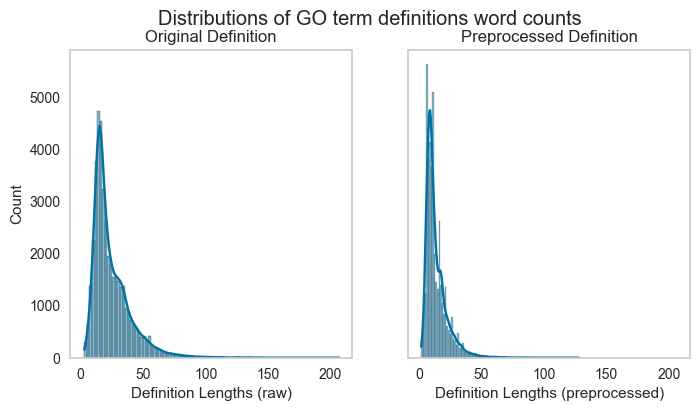

In [7]:
# Definitions lenght distribution and frequency

# Creates subplots
fig, axes = plt.subplots(1, 2, figsize=(8, 4), sharey=True, sharex=True)
fig.suptitle("Distributions of GO term definitions word counts")

# Plots words' count of raw text definitions
sns.histplot(go_df["def_word_count"].values, bins=100, kde=True, ax=axes[0])
axes[0].set_title("Original Definition")
axes[0].set_xlabel("Definition Lengths (raw)")
axes[0].grid(False)

# Plots words' count of preprocessed text definitions
go_hist = sns.histplot(
    go_df["preproc_word_count"].values, bins=100, kde=True, ax=axes[1]
)
axes[1].set_title("Preprocessed Definition")
axes[1].set_xlabel("Definition Lengths (preprocessed)")
axes[1].grid(False)

# save plot
plt.savefig(root / "draft/figures/go_def_word_count.png", transparent=True, dpi=300)
plt.show()

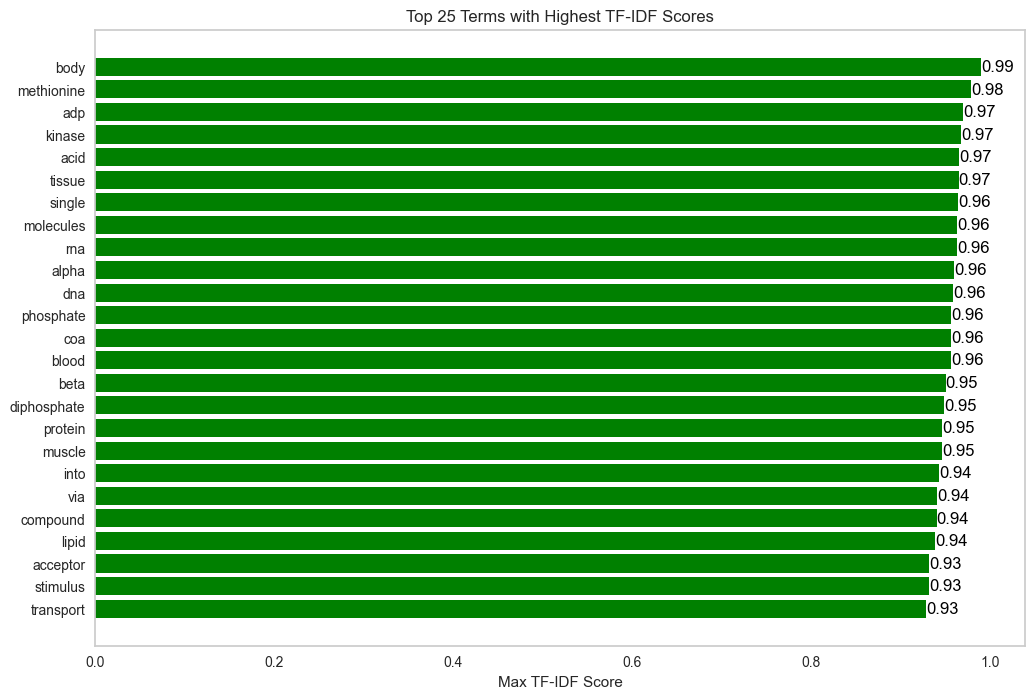

In [10]:
# TF-IDF

plot_tfidf(go_df["concat_text"], min_df=0.01)  # tipical min_df values 0.01 to 0.05

In [14]:
# Sampling for EDA without scaling (embeddings should be in range already)

go_df_sample = go_embeddings_df.sample(4000, random_state=42)
go_sample = go_df_sample.iloc[:, 1:-2].copy()

print(f"sampling shape: {go_df_sample.shape}")
print(f"embeddings (scaled) shape: {go_sample.shape}")
go_sample

sampling shape: (4000, 387)
embeddings (scaled) shape: (4000, 384)


,0,1,2,3,4,5,6,7,8,9,...,374,375,376,377,378,379,380,381,382,383
11359,0.065351,0.105332,-0.069797,-0.031918,-0.097911,-0.303514,-0.001486,0.185429,0.157673,0.029957,...,0.020155,0.233223,-0.291815,0.193987,0.130704,-0.105263,-0.288824,0.101011,0.408027,-0.154303
5148,0.072962,-0.017723,0.098959,-0.196236,0.079520,-0.065298,-0.064023,-0.006009,0.128897,0.240331,...,-0.138938,0.063620,0.051601,-0.207836,0.275209,-0.130346,-0.363483,0.336038,0.144612,-0.158095
41012,-0.070337,0.217106,-0.018819,-0.406962,0.003785,0.042356,0.151847,0.115071,-0.269751,0.073355,...,-0.056642,0.063254,0.104598,0.005271,0.109390,-0.098238,-0.084707,0.035077,0.320876,0.044499
41776,0.013198,0.318444,-0.184288,-0.076750,0.027692,-0.246055,0.134245,0.041325,0.040118,0.404941,...,-0.040044,0.318293,-0.244265,-0.038895,0.249554,-0.101746,-0.075734,-0.012070,0.232360,-0.110307
20258,0.004120,0.205353,0.005111,-0.057433,0.260868,-0.094404,0.150163,0.157817,0.009971,0.059599,...,0.013855,0.017431,-0.096968,0.077483,0.082579,0.107323,0.009083,0.223855,0.107096,-0.178197
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35536,-0.116605,0.128470,-0.144483,-0.051736,-0.005931,-0.140109,0.003699,0.190969,0.083795,-0.138842,...,0.045230,0.204052,-0.028055,-0.033801,-0.042371,-0.013371,-0.121888,-0.038693,0.392886,-0.365725
21772,-0.273455,-0.115885,0.039870,0.182582,0.107981,0.099342,0.299210,0.086772,-0.082211,-0.044361,...,-0.214131,-0.024774,0.050526,0.062278,-0.037830,-0.161815,-0.023386,-0.040036,0.396983,-0.169706
12788,0.008841,-0.025349,0.013674,0.043994,-0.138822,-0.283497,0.114837,0.070608,0.221580,0.117275,...,0.153502,0.189725,-0.066226,0.250299,-0.149772,-0.029112,-0.109415,0.300487,0.109680,-0.315462
38139,-0.142476,-0.098447,-0.074835,0.298856,0.101357,-0.106460,0.284957,-0.085867,0.151055,0.078821,...,-0.150070,0.261877,0.168046,0.112628,0.038801,-0.144288,0.024335,0.024122,0.436551,-0.468513


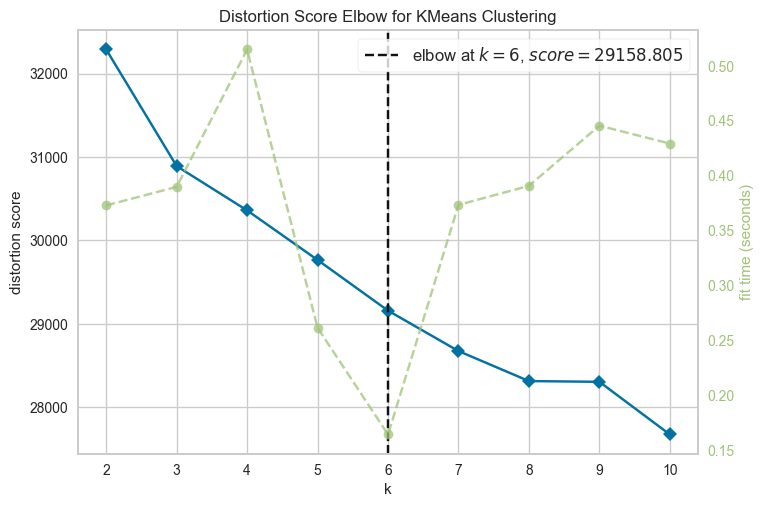

In [15]:
# clustering with elbow method to determine best num of clusters

# yellowbrick KMeans with elbow and viz
model = KElbowVisualizer(KMeans(n_init="auto"), k=10)

model.fit(go_sample)
model.show()
plt.show()

In [17]:
# find clusters

num_of_neighbors = (3, 5, 7)

for n in num_of_neighbors:
    clusterer = hdbscan.HDBSCAN(min_cluster_size=n)
    cluster_labels = clusterer.fit_predict(go_sample)

    # scoring clustering with silhouette
    scores = silhouette_score(go_sample, cluster_labels)
    print(
        f"# neighbors = {n}, # clusters = {len(np.unique(cluster_labels))} | Mean Silhouette Score = {scores:.2f}"
    )

# neighbors = 3, # clusters = 3 | Mean Silhouette Score = 0.10
# neighbors = 5, # clusters = 4 | Mean Silhouette Score = 0.02
# neighbors = 7, # clusters = 4 | Mean Silhouette Score = 0.02


In [18]:
# sklearn kmeans

num_clusters = 3  # estimated number of clusters with 2 or 3 neighbors

kmeans = KMeans(n_clusters=num_clusters, n_init="auto", random_state=42).fit(go_sample)

# add to tsne results
go_df_sample["kmeans_cluster"] = kmeans.labels_

# group mol_id by cluster
cluster_gols = (
    go_df_sample.groupby("kmeans_cluster")["go_id"].agg(lambda x: list(x)).sort_values()
)

# create df with clusters and number of items per cluster
cluster_gols_counts = pd.DataFrame(cluster_gols)
cluster_gols_counts.insert(0, "n_items", [len(x) for x in cluster_gols])
cluster_gols_counts.sort_values(by="n_items", ascending=False, inplace=True)
cluster_gols_counts.reset_index(drop=False, inplace=True)

# save metadata
cluster_gols_counts.to_csv("go_kmeans_clusters.csv", index=False)

# saving sampled dataset with clusters' ids
go_df_sample.to_csv("embeddings/go/go_embeddings_kmeans.csv", index=False)

print(f"Sampled GO embeddings shape: {go_df_sample.shape}")

print(go_df_sample.value_counts(subset=["aspect"]))

cluster_gols_counts

Sampled GO embeddings shape: (4000, 388)
aspect            
biological_process    2607
molecular_function    1004
cellular_component     389
Name: count, dtype: int64


,kmeans_cluster,n_items,go_id
0,1,1435,"[GO:0022009, GO:0008069, GO:0045117, GO:000083..."
1,0,1292,"[GO:1990889, GO:0004071, GO:0019374, GO:001962..."
2,2,1273,"[GO:2000790, GO:0045839, GO:1904189, GO:001022..."


### UMAP (Uniform Manifold Approximation and Projection for Dimension Reduction)

In [24]:
# UMAP with 3 components for 3D visualization (with dimensionality reduction)

# create a dictionary to store the outputs
umap_dict = {}

# parameters
n_neighbors_list = [3, 5, 15, 30]
min_dist_list = [0.0, 0.2, 0.99]
metrics = ["cosine", "euclidean", "manhattan"]
n_epochs = [1000]
learning_rate = 1

# for progress tracking
total_iterations = (
    len(n_neighbors_list) * len(min_dist_list) * len(metrics) * len(n_epochs)
)

parameter_combinations = product(n_neighbors_list, min_dist_list, metrics, n_epochs)


for n_neighbors, min_dist, metric, epoch in tqdm(
    parameter_combinations, total=total_iterations, desc="UMAP Parameter Search"
):

    reducer = umap.UMAP(
        n_components=3,
        n_neighbors=n_neighbors,
        metric=metric,
        n_epochs=epoch,
        learning_rate=learning_rate,
        min_dist=min_dist,
        verbose=False,
        random_state=42,
    )
    results = reducer.fit_transform(go_sample)

    # store results
    umap_dict.update({f"{n_neighbors}_{min_dist}_{metric}_{epoch}": results})


# create dataframe with results for ploting
# initialize df to concatenate
df_umap = pd.DataFrame()

# iterates of tsne results and add the columns
for key, value in umap_dict.items():
    df_umap = pd.concat([df_umap, pd.DataFrame(value)], axis=1)

# create column names
coordinates = ["x", "y", "z"]
columns_names = [
    f"{coordinate}_{str(n_neighbors)}_{str(min_dist)}_{metric}_{str(epoch)}"
    for n_neighbors in n_neighbors_list
    for min_dist in min_dist_list
    for metric in metrics
    for epoch in n_epochs
    for coordinate in coordinates
]

df_umap.columns = columns_names
df_umap = pd.concat(
    [
        go_df_sample[["go_id", "aspect", "name", "kmeans_cluster"]].reset_index(
            drop=True
        ),
        df_umap,
    ],
    axis=1,
)

# save grid search
df_umap.to_csv(
    root / "clustering/go/umap_grid_pca.csv",
    index=False,
)

print(df_umap.shape)
df_umap.head()

UMAP Parameter Search:   0%|          | 0/36 [00:00<?, ?it/s]

(4000, 112)


,go_id,aspect,name,kmeans_cluster,x_3_0.0_cosine_1000,y_3_0.0_cosine_1000,z_3_0.0_cosine_1000,x_3_0.0_euclidean_1000,y_3_0.0_euclidean_1000,z_3_0.0_euclidean_1000,...,z_30_0.2_manhattan_1000,x_30_0.99_cosine_1000,y_30_0.99_cosine_1000,z_30_0.99_cosine_1000,x_30_0.99_euclidean_1000,y_30_0.99_euclidean_1000,z_30_0.99_euclidean_1000,x_30_0.99_manhattan_1000,y_30_0.99_manhattan_1000,z_30_0.99_manhattan_1000
0,GO:0022009,biological_process,central nervous system vasculogenesis,1,-0.705014,-0.963809,5.057509,7.952394,3.459409,8.459386,...,-0.502562,12.946897,-5.034656,7.561080,15.243673,12.219558,-5.761312,16.148638,12.406816,-5.620537
1,GO:0008069,biological_process,"dorsal/ventral axis specification, ovarian fol...",1,2.232559,-2.517549,5.615920,5.671731,3.897148,4.024561,...,-1.044674,10.274924,-3.762765,7.611211,14.502497,14.103805,-5.630731,15.214910,12.572341,-7.155715
2,GO:1990889,molecular_function,H4K20me3 modified histone binding,0,6.653170,13.152905,6.378204,1.542455,-2.003327,0.029740,...,-4.932952,5.056131,-8.582211,6.165766,17.299524,17.028093,-11.000625,19.714558,11.785272,-12.712141
3,GO:2000790,biological_process,regulation of mesenchymal cell proliferation i...,2,-1.689293,-2.179451,6.331688,6.326581,4.511851,7.576757,...,-1.190643,12.449244,-4.182743,10.021400,12.541324,12.257197,-4.882867,14.334733,10.147019,-5.904750
4,GO:0045839,biological_process,negative regulation of mitotic nuclear division,2,0.839297,0.238958,7.562747,4.975642,4.504745,0.356316,...,-3.642953,8.043269,-4.187868,8.867290,11.769085,15.108573,-7.448495,15.308937,9.615036,-9.531939


In [25]:
# load umap grid search

df_umap = pd.read_csv(clustering_folder / "go/umap_grid_pca.csv")
df_umap.shape

(4000, 112)

In [39]:
# interactive plot

# plot
n_neighbors = 5
min_dist = 0.2
metric = "cosine"
epochs = 1000
width = 800
height = 600
size = 2
opacity = 0.8

# cluster labels
fig = px.scatter_3d(
    df_umap,
    x=f"x_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    y=f"y_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    z=f"z_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    color=df_umap["aspect"],
    labels={"color": "aspect"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

fig = px.scatter_3d(
    df_umap,
    x=f"x_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    y=f"y_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    z=f"z_{str(n_neighbors)}_{str(min_dist)}_{metric}_{epochs}",
    color=df_umap["kmeans_cluster"],
    labels={"color": "cluster"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

In [42]:
# UMAP single shot

# parameters
n_neighbors = 15
min_dist = 0.2
metric = "cosine"
epoch = 5000
learning_rate = 1
width = 800
height = 600
size = 2
opacity = 0.7

# fit data
reducer = umap.UMAP(
    n_components=3,
    n_neighbors=n_neighbors,
    metric=metric,
    n_epochs=epoch,
    learning_rate=learning_rate,
    min_dist=min_dist,
    verbose=False,
    random_state=42,
)
results = reducer.fit_transform(go_sample)

# add to df
df_umap_sample = pd.DataFrame(results, columns=["x", "y", "z"])

# add columns from go samples
df_umap_sample.insert(0, "go_id", np.array(go_df_sample["go_id"]))
df_umap_sample.insert(1, "aspect", np.array(go_df_sample["aspect"]))
df_umap_sample.insert(2, "name", np.array(go_df_sample["name"]))
df_umap_sample.insert(3, "kmeans_cluster", np.array(go_df_sample["kmeans_cluster"]))

# Save to CSV
df_umap_sample.to_csv(root / "clustering/go/umap_single_pca.csv", index=False)

# interactive plot
width = 800
height = 600

# aspect labels
fig = px.scatter_3d(
    df_umap_sample,
    x="x",
    y="y",
    z="z",
    color="aspect",
    labels={"color": "aspect"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)

fig.show()

# kmeans cluster labels
fig = px.scatter_3d(
    df_umap_sample,
    x="x",
    y="y",
    z="z",
    color="kmeans_cluster",
    labels={"color": "cluster"},
    hover_data=["name"],
)

fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)

fig.show()

In [ ]:
# Generates graph with UMAP results connect KNN neighbors

# Creates a Networkx graph object
new_go = nx.Graph()

# Add nodes with UMAP results as attributes
for idx, result in enumerate(results):
    new_go.add_node(idx, umap_pos=tuple(result))

# Use Nearest Neigbors to connect nodes
knn = NearestNeighbors(n_neighbors=30)
knn.fit(results)
distances, indices = knn.kneighbors(results)
print(distances, indices)

# Iterate over each item and its neighbors to add edges
for i, neighbors in enumerate(indices):
    for j, neighbor in enumerate(neighbors):
        if neighbor != i:  # exclude self-loops
            new_go.add_edge(i, neighbor, weight=distances[i][j])

new_go.nodes(data=True)

### t-SNE (t-distributed Stochastic Neighbor Embedding)

In [49]:
# t-SNE with 3 components for 3D visualization (with dimensionality reduction)

# create a dictionary to store the outputs
tsne_dict = {}

perplexities = [3, 5, 10, 20, 30]

for perplexity in tqdm(
    perplexities, total=len(perplexities), desc="Searching perplexity..."
):

    tsne = TSNE(
        n_components=3,
        perplexity=perplexity,
        learning_rate="auto",
        n_iter=5000,
        random_state=42,
        n_jobs=-1,
        metric="cosine",
    )
    results = tsne.fit_transform(go_sample)

    tsne_dict.update({perplexity: results})

# create dataframe with results for ploting
# initialize df to concatenate
df_tsne = pd.DataFrame()

# iterates of tsne results and add the columns
for key, value in tsne_dict.items():
    df_tsne = pd.concat([df_tsne, pd.DataFrame(value)], axis=1)

# create column names
coordinates = ["x", "y", "z"]
columns_names = [
    f"{item2}_{str(item1)}" for item1 in perplexities for item2 in coordinates
]

df_tsne.columns = columns_names

# add data to go_df_sample dataframe
df_tsne = pd.concat(
    [
        go_df_sample[["go_id", "name", "aspect", "kmeans_cluster"]].reset_index(
            drop=True
        ),
        df_tsne,
    ],
    axis=1,
)

# save grid search
df_tsne.to_csv(clustering_folder / "go" / "tsne_grid_pca.csv", index=False)

print(df_tsne.shape)
df_tsne.head()

Searching perplexity...:   0%|          | 0/5 [00:00<?, ?it/s]

(4000, 19)


,go_id,name,aspect,kmeans_cluster,x_3,y_3,z_3,x_5,y_5,z_5,x_10,y_10,z_10,x_20,y_20,z_20,x_30,y_30,z_30
0,GO:0022009,central nervous system vasculogenesis,biological_process,1,-29.547476,-15.758795,5.172114,-31.168125,-12.132307,5.602833,-24.094618,-4.316130,-15.531500,-46.782818,-5.391560,5.390201,-29.369450,6.157552,12.147902
1,GO:0008069,"dorsal/ventral axis specification, ovarian fol...",biological_process,1,-37.446918,20.636457,10.736033,-30.482630,17.120676,2.072580,-32.715309,12.538334,-2.535990,-23.412231,34.097168,-1.425100,-42.995697,19.992800,-16.080782
2,GO:1990889,H4K20me3 modified histone binding,molecular_function,0,23.667639,22.814631,17.034084,23.300716,26.507540,4.321532,38.049175,11.122519,3.899120,44.538387,14.980618,-10.370687,33.010864,-21.325560,-19.325766
3,GO:2000790,regulation of mesenchymal cell proliferation i...,biological_process,2,-43.945972,-15.519004,-17.483465,-38.873936,-10.461884,-16.571840,-32.501362,-9.470438,-12.307938,-49.241325,11.178363,-10.935589,-35.604050,15.166659,12.842215
4,GO:0045839,negative regulation of mitotic nuclear division,biological_process,2,-20.514374,14.748797,24.070295,-18.287916,23.493832,22.065891,-12.794610,12.490804,22.755880,-5.920179,29.569685,-13.897183,-13.565437,1.573527,-30.443081


In [44]:
# load tsne grid search

df_tsne = pd.read_csv(clustering_folder / "go" / "tsne_grid_pca.csv")
df_tsne.shape

(4000, 19)

In [50]:
# interactive plot

# plot
p = "5"  # perplexity

width = 800
height = 600
size = 2
opacity = 0.7


# label: aspect
fig = px.scatter_3d(
    df_tsne,
    x=f"x_{p}",
    y=f"y_{p}",
    z=f"z_{p}",
    color=df_tsne["aspect"],
    labels={"color": "cluster"},
    hover_data=["name"],
)

fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

# label: cluster
fig = px.scatter_3d(
    df_tsne,
    x=f"x_{p}",
    y=f"y_{p}",
    z=f"z_{p}",
    color=df_tsne["kmeans_cluster"],
    labels={"color": "cluster"},
    hover_data=["name"],
)

fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

### Spectral Embedding (Spectral embedding for non-linear dimensionality reduction using Laplacian Eigenmaps)

**References**
>“Laplacian Eigenmaps for Dimensionality Reduction and Data Representation” M. Belkin, P. Niyogi, Neural Computation, June 2003; 15 (6):1373-1396

In [20]:
# spectral embedding

# create a dictionary to store the outputs
se_dict = {}

n_neighbors = [3, 5, 10, 20, 30, 50, 100]

for n_neighbor in tqdm(
    n_neighbors, total=len(n_neighbors), desc="Searching n_neighbors..."
):

    se = SpectralEmbedding(
        n_components=3,
        n_neighbors=n_neighbor,
        affinity="rbf",
        random_state=42,
        n_jobs=-1,
    )
    results = se.fit_transform(go_sample)

    se_dict.update({n_neighbor: results})


# create dataframe with results for ploting
# initialize df to concatenate
df_se = pd.DataFrame()

# iterates of tsne results and add the columns
for key, value in se_dict.items():
    df_se = pd.concat([df_se, pd.DataFrame(value)], axis=1)

# create column names
coordinates = ["x", "y", "z"]
columns_names = [
    f"{item2}_{str(item1)}" for item1 in n_neighbors for item2 in coordinates
]

df_se.columns = columns_names

# add data to go_df_sample dataframe
df_se = pd.concat(
    [
        go_df_sample[["go_id", "name", "aspect", "kmeans_cluster"]].reset_index(
            drop=True
        ),
        df_se,
    ],
    axis=1,
)

# save grid search
df_se.to_csv(root / "clustering/go/se_grid.csv", index=False)

print(df_se.shape)
df_se.head()

Searching n_neighbors...:   0%|          | 0/7 [00:00<?, ?it/s]

(4000, 25)


,go_id,name,aspect,kmeans_cluster,x_3,y_3,z_3,x_5,y_5,z_5,...,z_20,x_30,y_30,z_30,x_50,y_50,z_50,x_100,y_100,z_100
0,GO:0022009,central nervous system vasculogenesis,biological_process,1,-0.000265,0.000291,-0.000328,-0.000265,0.000291,-0.000328,...,-0.000328,-0.000265,0.000291,-0.000328,-0.000265,0.000291,-0.000328,-0.000265,0.000291,-0.000328
1,GO:0008069,"dorsal/ventral axis specification, ovarian fol...",biological_process,1,-0.000123,0.000153,-0.000175,-0.000123,0.000153,-0.000175,...,-0.000175,-0.000123,0.000153,-0.000175,-0.000123,0.000153,-0.000175,-0.000123,0.000153,-0.000175
2,GO:1990889,H4K20me3 modified histone binding,molecular_function,0,0.000355,0.000142,0.000338,0.000355,0.000142,0.000338,...,0.000338,0.000355,0.000142,0.000338,0.000355,0.000142,0.000338,0.000355,0.000142,0.000338
3,GO:2000790,regulation of mesenchymal cell proliferation i...,biological_process,2,-0.000344,0.000061,0.000042,-0.000344,0.000061,0.000042,...,0.000042,-0.000344,0.000061,0.000042,-0.000344,0.000061,0.000042,-0.000344,0.000061,0.000042
4,GO:0045839,negative regulation of mitotic nuclear division,biological_process,2,-0.000206,-0.000172,0.000231,-0.000206,-0.000172,0.000231,...,0.000231,-0.000206,-0.000172,0.000231,-0.000206,-0.000172,0.000231,-0.000206,-0.000172,0.000231


In [21]:
# load tsne grid search

df_se = pd.read_csv(root / "clustering/go/se_grid.csv")
df_se.shape

(4000, 25)

In [23]:
# interactive plot

# plot
p = "100"  # n_neighbors

width = 800
height = 600
size = 2
opacity = 0.7

# label: aspect
fig = px.scatter_3d(
    df_se,
    x=f"x_{p}",
    y=f"y_{p}",
    z=f"z_{p}",
    color=df_se["aspect"],
    labels={"color": "aspect"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()

# label: cluster
fig = px.scatter_3d(
    df_se,
    x=f"x_{p}",
    y=f"y_{p}",
    z=f"z_{p}",
    color=df_se["kmeans_cluster"],
    labels={"color": "cluster"},
    hover_data=["name"],
)
fig.update_traces(marker=dict(size=size), opacity=opacity)
fig.update_layout(width=width, height=height)
fig.show()